<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet%202%20PBL/Praktikum%201%20(JS2)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 0 - Persiapan Lingkungan

In [1]:
!pip install -q pandas matplotlib numpy seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Langkah 1 - Memuat Data

In [3]:
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

In [4]:
df_cafes.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,NaN,2026-10-11T13:55:10.909678,cafe Kota Malang
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],NaN,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang


In [5]:
df_reviews.head()

,review_id,cafe_id,author_name,rating,text,published_at,likes,scraped_at
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536
2,6f1a2d5a-01c1-4fc9-8cfb-c4f5c8f58ec1,ba4b512c-fa2d-4959-8384-8570c81121ec,Nico Julianda,5.0,"comfort places for everything i did, mulai dar...",22 menit lalu,0,2026-10-11T13:54:49.854029
3,fd86734a-dcef-4f6d-8251-e47b203c0199,ba4b512c-fa2d-4959-8384-8570c81121ec,nazira parsa_04,5.0,"minumannya enak"", tempatnya comfy. worth to try",23 menit lalu,0,2026-10-11T13:54:49.967848
4,cdeda318-e583-4473-9fd0-4e4b48b56e16,ba4b512c-fa2d-4959-8384-8570c81121ec,dulkamdi dul,5.0,"kopian 24jam enak banget kalau dibuat wfc, tem...",28 menit lalu,0,2026-10-11T13:54:50.058719


#Langkah 2 - Inspeksi Data

##Pengecekan Dimensi

In [6]:
print("Dimensi Cafes:", df_cafes.shape)
print("Dimensi Reviews:", df_reviews.shape)

Dimensi Cafes: (99, 12)
Dimensi Reviews: (2230, 8)


##Pengecekan Tipe Data

###Untuk Dataset Cafe (df_cafes):

In [7]:
df_cafes.info()
df_cafes.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   cafe_id       99 non-null     object 
 1   name          99 non-null     object 
 2   address       99 non-null     object 
 3   latitude      99 non-null     float64
 4   longitude     99 non-null     float64
 5   rating        99 non-null     float64
 6   review_count  99 non-null     int64  
 7   categories    99 non-null     object 
 8   phone         78 non-null     object 
 9   website       54 non-null     object 
 10  scraped_at    99 non-null     object 
 11  source_query  99 non-null     object 
dtypes: float64(3), int64(1), object(8)
memory usage: 9.4+ KB


,0
cafe_id,0
name,0
address,0
latitude,0
longitude,0
rating,0
review_count,0
categories,0
phone,21
website,45


###Untuk Dataset Review (df_reviews):

In [8]:
df_reviews.info()
df_reviews.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2230 entries, 0 to 2229
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   review_id     2230 non-null   object 
 1   cafe_id       2230 non-null   object 
 2   author_name   2230 non-null   object 
 3   rating        2230 non-null   float64
 4   text          2230 non-null   object 
 5   published_at  2230 non-null   object 
 6   likes         2230 non-null   int64  
 7   scraped_at    2230 non-null   object 
dtypes: float64(1), int64(1), object(6)
memory usage: 139.5+ KB


,0
review_id,0
cafe_id,0
author_name,0
rating,0
text,0
published_at,0
likes,0
scraped_at,0


##Ringkasan Nilai Statistik Deskriptif

In [9]:
df_cafes.describe()

,latitude,longitude,rating,review_count
count,99.000000,99.000000,99.000000,99.000000
mean,-7.964147,112.627635,4.657576,898.444444
std,0.010800,0.007370,0.177908,1223.031615
min,-7.985575,112.607256,4.200000,1.000000
25%,-7.972555,112.622702,4.550000,153.000000
50%,-7.965777,112.627146,4.700000,533.000000
75%,-7.960050,112.632919,4.800000,1098.000000
max,-7.932842,112.651831,5.000000,6014.000000


In [10]:
df_reviews.describe()

,rating,likes
count,2230.000000,2230.000000
mean,4.553363,0.037220
std,1.076097,0.255852
min,1.000000,0.000000
25%,5.000000,0.000000
50%,5.000000,0.000000
75%,5.000000,0.000000
max,5.000000,4.000000


#Langkah 3 - Inspeksi Visual


##Inspeksi Distribusi Data

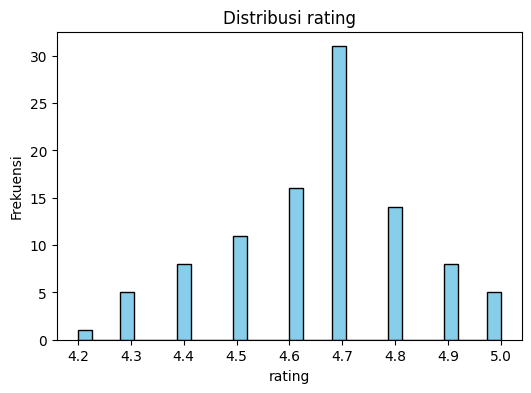

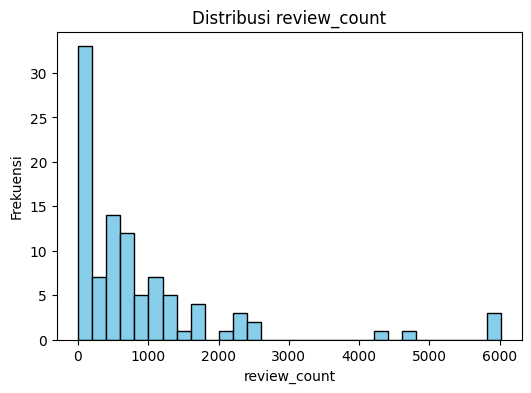

In [11]:
num_cols = ['rating', 'review_count']
for col in num_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(df_cafes[col].dropna(), bins=30, color='skyblue', edgecolor='black')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

##Inspeksi Outlier

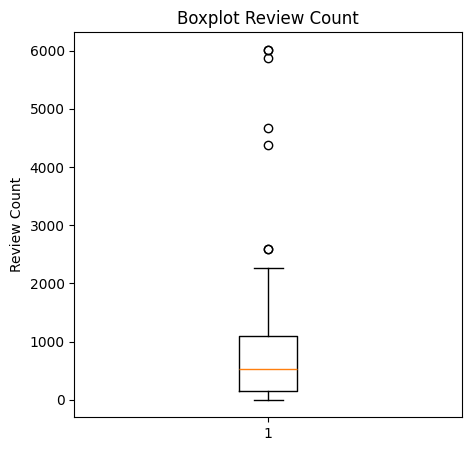

In [12]:
plt.figure(figsize=(5, 5))
plt.boxplot(df_cafes['review_count'].dropna(), vert=True)
plt.title('Boxplot Review Count')
plt.ylabel('Review Count')
plt.show()

##Inspeksi Komposisi Variabel Kualitatif

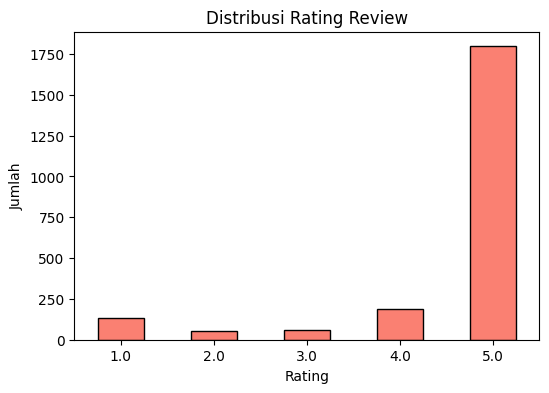

In [13]:
plt.figure(figsize=(6, 4))
df_reviews['rating'].value_counts().sort_index().plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Distribusi Rating Review')
plt.xlabel('Rating')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.show()

##Inspeksi Korelasi

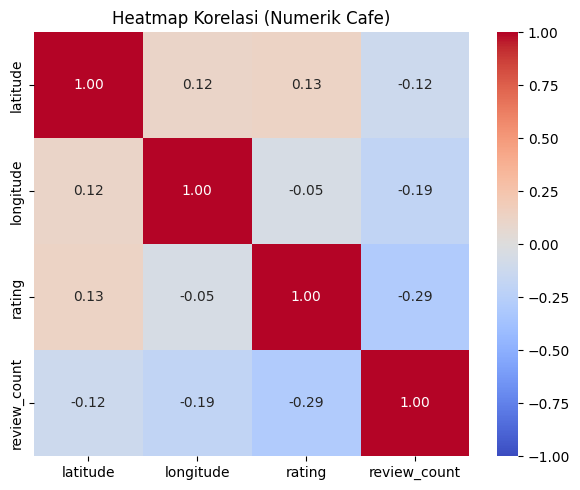

In [14]:
num_only = df_cafes.select_dtypes(include=[np.number])
corr = num_only.corr(numeric_only=True)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title('Heatmap Korelasi (Numerik Cafe)')
plt.tight_layout()
plt.show()

In [15]:
corr['rating'].sort_values(ascending=False)

,rating
rating,1.000000
latitude,0.126865
longitude,-0.054575
review_count,-0.289855


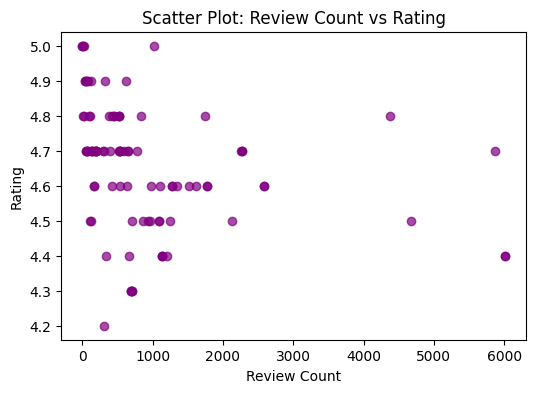

In [16]:
plt.figure(figsize=(6, 4))
plt.scatter(df_cafes['review_count'], df_cafes['rating'], alpha=0.7, color='purple')
plt.xlabel('Review Count')
plt.ylabel('Rating')
plt.title('Scatter Plot: Review Count vs Rating')
plt.show()